<a href="https://colab.research.google.com/github/andriyanooo/Implementasi-Processing-Data/blob/main/Olah_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import Library


In [1]:
!pip install geopandas shapely pyproj fiona scikit-learn -q

In [2]:
from google.colab import drive

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import os
import urllib.request

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


# 2. Load Data Mentah

In [3]:
drive.mount('/content/drive')
path_dataset = '/content/drive/MyDrive/SKRIPSI/Data Gempa/Salinan Data Backup asli.xlsx'
df_raw = pd.read_excel(path_dataset)

print("Dataset berhasil dimuat.")

Mounted at /content/drive
Dataset berhasil dimuat.


In [4]:
print('Jumlah Data :', df_raw.shape[0])
print('Jumlah Kolom :', df_raw.shape[1])
df_raw.head()

Jumlah Data : 63780
Jumlah Kolom : 12


,No,Event ID,Date time,Latitude,Longitude,Magnitude,Mag Type,Depth (km),Phase Count,Azimuth Gap,Location,Agency
0,1,bmg2020ccqw,2020-01-30T21:53:06.872494Z,-1.9822,99.8787,4.8480,M,50,104,123.7005,"Southern Sumatra, Indonesia",BMKG
1,2,bmg2020ccpk,2020-01-30T21:07:52.349556Z,-7.1532,122.2539,3.4545,M,10,9,173.4820,Flores Sea,BMKG
2,3,bmg2020ccmh,2020-01-30T19:32:48.5943Z,2.4583,98.9948,4.1108,M,142,23,106.1382,"Northern Sumatra, Indonesia",BMKG
3,4,bmg2020cchn,2020-01-30T17:08:59.590139Z,-8.3218,118.0571,4.1585,M,207,32,109.2949,"Sumbawa Region, Indonesia",BMKG
4,5,bmg2020ccen,2020-01-30T15:37:07.078598Z,-0.3861,124.0794,4.3291,M,57,38,73.8748,Southern Molucca Sea,BMKG


# Pra-pemrosesan Data


# 3. Seleksi Data


In [5]:
df_selected = df_raw.copy()

print("Kolom yang dipakai:", df_selected.columns.tolist())
print("Jumlah kolom:", len(df_selected.columns))

Kolom yang dipakai: ['No', 'Event ID', 'Date time', 'Latitude', 'Longitude', 'Magnitude', 'Mag Type', 'Depth (km)', 'Phase Count', 'Azimuth Gap', 'Location', 'Agency']
Jumlah kolom: 12


In [6]:
LAT_MIN, LAT_MAX = -11, 6
LON_MIN, LON_MAX = 95, 141

df_selected = df_selected[
    (df_selected["Latitude"].between(LAT_MIN, LAT_MAX)) &
    (df_selected["Longitude"].between(LON_MIN, LON_MAX))
]

print("Jumlah data setelah seleksi wilayah Indonesia:", len(df_selected))

Jumlah data setelah seleksi wilayah Indonesia: 63780


# 4. Pembersihan Data

In [7]:
data_quality_df = pd.DataFrame({
    "Kolom": df_selected.columns,
    "Jumlah Missing Value": df_selected.isnull().sum().values,
    "Jumlah Nilai Nol (0)": (df_selected == 0).sum().values
})

print("Tabel Pemeriksaan Missing Value dan Nilai Nol (0)")
display(data_quality_df)

duplicate_df = pd.DataFrame({
    "Keterangan": ["Jumlah Data Duplikat"],
    "Jumlah": [df_selected.duplicated().sum()]
})

print("\nTabel Data Duplikat")
display(duplicate_df)

Tabel Pemeriksaan Missing Value dan Nilai Nol (0)


,Kolom,Jumlah Missing Value,Jumlah Nilai Nol (0)
0,No,0,0
1,Event ID,0,0
2,Date time,0,0
3,Latitude,0,0
4,Longitude,0,0
5,Magnitude,0,0
6,Mag Type,0,0
7,Depth (km),0,1
8,Phase Count,0,0
9,Azimuth Gap,0,0



Tabel Data Duplikat


,Keterangan,Jumlah
0,Jumlah Data Duplikat,0


In [8]:
print("=== Data dengan Missing Value (Location) ===")
missing_location = df_selected[df_selected["Location"].isnull()]
display(missing_location)

print("\n=== Data dengan Nilai Depth (km) = 0 ===")
zero_depth = df_selected[df_selected["Depth (km)"] == 0]
display(zero_depth)

print("\n=== Data Bermasalah (Missing Location ATAU Depth = 0) ===")
data_bermasalah = df_selected[
    (df_selected["Location"].isnull()) | (df_selected["Depth (km)"] == 0)
]
display(data_bermasalah)

=== Data dengan Missing Value (Location) ===


,No,Event ID,Date time,Latitude,Longitude,Magnitude,Mag Type,Depth (km),Phase Count,Azimuth Gap,Location,Agency
32612,129,bmg2023kebd,2023-05-25T12:29:06.648422Z,-7.8166,123.2208,3.8440,M,11,38,96.7607,NaN,BMKG
32828,345,bmg2023jltk,2023-05-15T12:07:48.386638Z,2.2869,128.3825,3.2538,MLv,210,21,236.7893,NaN,BMKG
32938,455,bmg2023jcqx,2023-05-10T12:37:50.902814Z,-6.4703,104.8995,3.6680,MLv,10,58,197.3153,NaN,BMKG
34874,77,bmg2023quvk,2023-08-28T02:06:23.175708Z,-3.7859,140.2540,4.1969,MLv,10,20,124.3004,NaN,BMKG
37117,12,bmg2023xjvi,2023-11-29T16:19:44.205363Z,-8.8188,110.3480,3.0282,M,18,24,249.8481,NaN,BMKG
37630,526,bmg2023wkip,2023-11-15T17:29:02.280576Z,1.9276,127.2832,3.1829,MLv,89,29,154.9719,NaN,BMKG
38040,937,bmg2023vtol,2023-11-06T13:08:08.518658Z,-1.3838,126.3583,4.5438,MLv,12,86,37.1308,NaN,BMKG
41115,377,bmg2024fkrd,2024-03-17T23:41:41.796105Z,4.8340,127.3134,4.8929,mb,115,50,170.4441,NaN,BMKG
42978,294,bmg2024ljes,2024-06-10T13:30:13.47154Z,-2.5340,120.7782,2.7105,M,8,58,80.9737,NaN,BMKG
42979,295,bmg2024lizd,2024-06-10T10:41:15.154822Z,1.1860,126.1811,4.3944,M,32,78,43.3691,NaN,BMKG



=== Data dengan Nilai Depth (km) = 0 ===


,No,Event ID,Date time,Latitude,Longitude,Magnitude,Mag Type,Depth (km),Phase Count,Azimuth Gap,Location,Agency
57875,78,bmg2025szzw,2025-09-28T09:07:00.662308Z,-1.9778,119.4117,2.5615,M,0,7,166.9416,"Sulawesi, Indonesia",BMKG



=== Data Bermasalah (Missing Location ATAU Depth = 0) ===


,No,Event ID,Date time,Latitude,Longitude,Magnitude,Mag Type,Depth (km),Phase Count,Azimuth Gap,Location,Agency
32612,129,bmg2023kebd,2023-05-25T12:29:06.648422Z,-7.8166,123.2208,3.8440,M,11,38,96.7607,NaN,BMKG
32828,345,bmg2023jltk,2023-05-15T12:07:48.386638Z,2.2869,128.3825,3.2538,MLv,210,21,236.7893,NaN,BMKG
32938,455,bmg2023jcqx,2023-05-10T12:37:50.902814Z,-6.4703,104.8995,3.6680,MLv,10,58,197.3153,NaN,BMKG
34874,77,bmg2023quvk,2023-08-28T02:06:23.175708Z,-3.7859,140.2540,4.1969,MLv,10,20,124.3004,NaN,BMKG
37117,12,bmg2023xjvi,2023-11-29T16:19:44.205363Z,-8.8188,110.3480,3.0282,M,18,24,249.8481,NaN,BMKG
37630,526,bmg2023wkip,2023-11-15T17:29:02.280576Z,1.9276,127.2832,3.1829,MLv,89,29,154.9719,NaN,BMKG
38040,937,bmg2023vtol,2023-11-06T13:08:08.518658Z,-1.3838,126.3583,4.5438,MLv,12,86,37.1308,NaN,BMKG
41115,377,bmg2024fkrd,2024-03-17T23:41:41.796105Z,4.8340,127.3134,4.8929,mb,115,50,170.4441,NaN,BMKG
42978,294,bmg2024ljes,2024-06-10T13:30:13.47154Z,-2.5340,120.7782,2.7105,M,8,58,80.9737,NaN,BMKG
42979,295,bmg2024lizd,2024-06-10T10:41:15.154822Z,1.1860,126.1811,4.3944,M,32,78,43.3691,NaN,BMKG


In [9]:
n_sebelum = len(df_selected)

df_selected = df_selected[df_selected["Depth (km)"] > 0].copy().reset_index(drop=True)

print(f"Jumlah data sebelum pembersihan: {n_sebelum}")
print(f"Jumlah data setelah menghapus Depth = 0: {len(df_selected)}")
print(f"Data Depth = 0 yang dibuang: {n_sebelum - len(df_selected)}")

Jumlah data sebelum pembersihan: 63780
Jumlah data setelah menghapus Depth = 0: 63779
Data Depth = 0 yang dibuang: 1


In [10]:
print("Magnitude < 0 :", (df_selected["Magnitude"] < 0).sum())
print("Magnitude > 10 :", (df_selected["Magnitude"] > 10).sum())

print("Depth < 0 :", (df_selected["Depth (km)"] < 0).sum())
print("Depth > 700 :", (df_selected["Depth (km)"] > 700).sum())

Magnitude < 0 : 0
Magnitude > 10 : 0
Depth < 0 : 0
Depth > 700 : 0


In [11]:

os.makedirs("boundary_data", exist_ok=True)

base_url = "https://raw.githubusercontent.com/mahendrayudha/indonesia-geojson/main/Indonesia/Kabupaten-Kota/"
files = [
    "Kabupaten-Kota%20(Indonesia).shp",
    "Kabupaten-Kota%20(Indonesia).dbf",
    "Kabupaten-Kota%20(Indonesia).shx",
    "Kabupaten-Kota%20(Indonesia).prj",
]
for f in files:
    fname = f.replace("%20", " ")
    local_path = f"boundary_data/{fname}"
    if not os.path.exists(local_path):
        urllib.request.urlretrieve(base_url + f, local_path)

kab = gpd.read_file("boundary_data/Kabupaten-Kota (Indonesia).shp")
kab = kab[["NAME_1", "NAME_2", "TYPE_2", "geometry"]].rename(columns={
    "NAME_1": "Provinsi",
    "NAME_2": "Kabupaten_Kota",
    "TYPE_2": "Tipe_Wilayah",
})

print("Jumlah poligon kabupaten/kota dimuat:", len(kab))


Jumlah poligon kabupaten/kota dimuat: 502


In [12]:
gdf_points = gpd.GeoDataFrame(
    df_selected.copy(),
    geometry=gpd.points_from_xy(df_selected["Longitude"], df_selected["Latitude"]),
    crs="EPSG:4326",
)

joined = gpd.sjoin(gdf_points, kab, how="left", predicate="within")
joined = joined.drop(columns=["index_right"])

print(f"Titik yang berhasil dapat wilayah darat langsung: {joined['Provinsi'].notna().sum()} dari {len(joined)}")

Titik yang berhasil dapat wilayah darat langsung: 21666 dari 63779


In [13]:
sea_mask = joined["Provinsi"].isna()
sea_pts = joined.loc[sea_mask, ["geometry"]].copy()

kab_proj = kab.to_crs(3395)
sea_proj = sea_pts.to_crs(3395)

nearest_sea = gpd.sjoin_nearest(sea_proj, kab_proj, how="left", distance_col="dist_m")
nearest_sea = nearest_sea[~nearest_sea.index.duplicated(keep="first")]
nearest_sea["dist_km"] = nearest_sea["dist_m"] / 1000

joined.loc[sea_mask, "Provinsi_Terdekat"] = nearest_sea.loc[sea_mask.index[sea_mask], "Provinsi"].values
joined.loc[sea_mask, "Kabupaten_Kota_Terdekat"] = nearest_sea.loc[sea_mask.index[sea_mask], "Kabupaten_Kota"].values
joined.loc[sea_mask, "Jarak_ke_Daratan_km"] = nearest_sea.loc[sea_mask.index[sea_mask], "dist_km"].values

print(f"Titik laut yang diberi wilayah pesisir terdekat: {sea_mask.sum()}")


Titik laut yang diberi wilayah pesisir terdekat: 42113


In [14]:
joined["Status_Wilayah"] = joined["Provinsi"].notna().map({True: "Darat", False: "Laut"})

def buat_label_wilayah(row):
    if row["Status_Wilayah"] == "Darat":
        return f"{row['Kabupaten_Kota']} ({row['Tipe_Wilayah']}), {row['Provinsi']}"
    else:
        return (f"Laut - {row['Location']} "
                f"(terdekat: {row['Kabupaten_Kota_Terdekat']}, {row['Provinsi_Terdekat']}, "
                f"~{row['Jarak_ke_Daratan_km']:.1f} km dari pantai)")

joined["Wilayah_Detail"] = joined.apply(buat_label_wilayah, axis=1)

df_preprocessed = joined.drop(columns=["geometry"]).reset_index(drop=True)
print("Geocoding wilayah selesai.")


Geocoding wilayah selesai.


In [15]:
fitur_gempa = df_preprocessed[['Magnitude', 'Depth (km)', 'Azimuth Gap']]
fitur_gempa.head()

,Magnitude,Depth (km),Azimuth Gap
0,4.8480,50,123.7005
1,3.4545,10,173.4820
2,4.1108,142,106.1382
3,4.1585,207,109.2949
4,4.3291,57,73.8748


In [16]:
fitur_gempa.describe()

,Magnitude,Depth (km),Azimuth Gap
count,"63,779.0000","63,779.0000","63,779.0000"
mean,3.3241,39.8597,137.6079
std,0.8475,52.2283,62.5770
min,0.1912,1.0000,8.6068
25%,2.7234,10.0000,85.9663
50%,3.2312,14.0000,127.7603
75%,3.8480,43.0000,186.3066
max,7.8947,300.0000,351.9458


In [17]:
scaler = MinMaxScaler()
df_norm = pd.DataFrame(
    scaler.fit_transform(fitur_gempa),
    columns=fitur_gempa.columns
)

print('Data Setelah Normalisasi')
df_norm.head()

Data Setelah Normalisasi


,Magnitude,Depth (km),Azimuth Gap
0,0.6045,0.1639,0.3352
1,0.4236,0.0301,0.4802
2,0.5088,0.4716,0.2841
3,0.5150,0.6890,0.2933
4,0.5372,0.1873,0.1901


#6. Data Hasil Pra-pemrosesan

In [18]:
print("===== Hasil Geocoding Wilayah =====")
display(df_preprocessed.head(5))
print("===== Statistik Deskriptif Hasil Normalisasi =====")
display(df_norm.describe().round(4))

===== Hasil Geocoding Wilayah =====


,No,Event ID,Date time,Latitude,Longitude,Magnitude,Mag Type,Depth (km),Phase Count,Azimuth Gap,Location,Agency,Provinsi,Kabupaten_Kota,Tipe_Wilayah,Provinsi_Terdekat,Kabupaten_Kota_Terdekat,Jarak_ke_Daratan_km,Status_Wilayah,Wilayah_Detail
0,1,bmg2020ccqw,2020-01-30T21:53:06.872494Z,-1.9822,99.8787,4.8480,M,50,104,123.7005,"Southern Sumatra, Indonesia",BMKG,NaN,NaN,NaN,Sumatera Barat,Kepulauan Mentawai,22.7457,Laut,"Laut - Southern Sumatra, Indonesia (terdekat: ..."
1,2,bmg2020ccpk,2020-01-30T21:07:52.349556Z,-7.1532,122.2539,3.4545,M,10,9,173.4820,Flores Sea,BMKG,NaN,NaN,NaN,Sulawesi Selatan,Kepulauan Selayar,51.0398,Laut,Laut - Flores Sea (terdekat: Kepulauan Selayar...
2,3,bmg2020ccmh,2020-01-30T19:32:48.5943Z,2.4583,98.9948,4.1108,M,142,23,106.1382,"Northern Sumatra, Indonesia",BMKG,Sumatera Utara,Lake Toba,Water Body,NaN,NaN,NaN,Darat,"Lake Toba (Water Body), Sumatera Utara"
3,4,bmg2020cchn,2020-01-30T17:08:59.590139Z,-8.3218,118.0571,4.1585,M,207,32,109.2949,"Sumbawa Region, Indonesia",BMKG,Nusa Tenggara Barat,Bima,Kabupaten,NaN,NaN,NaN,Darat,"Bima (Kabupaten), Nusa Tenggara Barat"
4,5,bmg2020ccen,2020-01-30T15:37:07.078598Z,-0.3861,124.0794,4.3291,M,57,38,73.8748,Southern Molucca Sea,BMKG,NaN,NaN,NaN,Sulawesi Tengah,Banggai,79.3096,Laut,Laut - Southern Molucca Sea (terdekat: Banggai...


===== Statistik Deskriptif Hasil Normalisasi =====


,Magnitude,Depth (km),Azimuth Gap
count,"63,779.0000","63,779.0000","63,779.0000"
mean,0.4067,0.1300,0.3757
std,0.1100,0.1747,0.1823
min,0.0000,0.0000,0.0000
25%,0.3287,0.0301,0.2253
50%,0.3946,0.0435,0.3470
75%,0.4747,0.1405,0.5176
max,1.0000,1.0000,1.0000


#7. PENERAPAN ALGORITMA K-MEANS

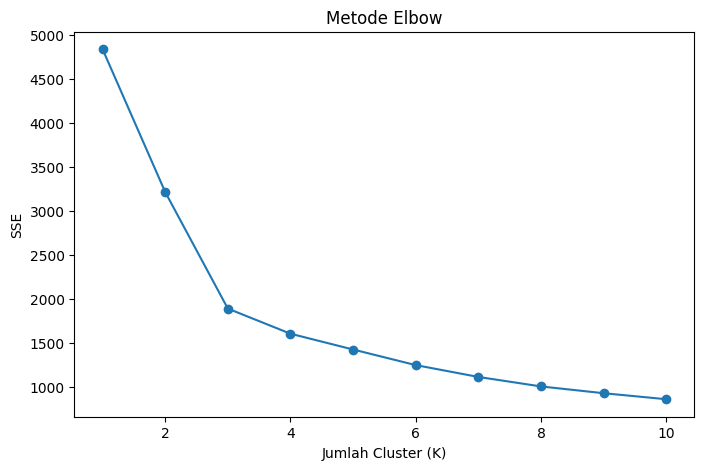

,K,SSE
0,1,"4,836.5477"
1,2,"3,213.3057"
2,3,"1,888.8095"
3,4,"1,603.3956"
4,5,"1,423.8315"
5,6,"1,246.6706"
6,7,"1,112.1873"
7,8,"1,004.2842"
8,9,927.2145
9,10,858.9018


In [19]:
inertia = []
K_range = range(1,11)

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(df_norm)
    inertia.append(model.inertia_)

plt.figure(figsize=(8,5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('SSE')
plt.title('Metode Elbow')
plt.show()

sse_table = pd.DataFrame({'K': list(K_range), 'SSE': inertia})
sse_table

In [20]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
labels = kmeans.fit_predict(df_norm)

df_cluster_result = fitur_gempa.copy()
df_cluster_result['cluster_label'] = labels

df_cluster_result.head()

,Magnitude,Depth (km),Azimuth Gap,cluster_label
0,4.8480,50,123.7005,1
1,3.4545,10,173.4820,2
2,4.1108,142,106.1382,0
3,4.1585,207,109.2949,0
4,4.3291,57,73.8748,1


In [21]:
from IPython.display import display

print("===== 5 Data Awal =====")
display(df_cluster_result.head())

print("===== 5 Data Akhir =====")
display(df_cluster_result.tail())

===== 5 Data Awal =====


,Magnitude,Depth (km),Azimuth Gap,cluster_label
0,4.8480,50,123.7005,1
1,3.4545,10,173.4820,2
2,4.1108,142,106.1382,0
3,4.1585,207,109.2949,0
4,4.3291,57,73.8748,1


===== 5 Data Akhir =====


,Magnitude,Depth (km),Azimuth Gap,cluster_label
63774,2.9665,99,109.6918,0
63775,3.0823,1,83.9769,1
63776,3.4910,97,169.1919,0
63777,2.6438,25,221.3553,2
63778,3.2645,1,92.0944,1


In [22]:
df_cluster_result.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63779 entries, 0 to 63778
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Magnitude      63779 non-null  float64
 1   Depth (km)     63779 non-null  int64  
 2   Azimuth Gap    63779 non-null  float64
 3   cluster_label  63779 non-null  int32  
dtypes: float64(2), int32(1), int64(1)
memory usage: 1.7 MB


## 10. Evaluasi Hasil

Tahap ini menilai kualitas klaster yang terbentuk dan menginterpretasikannya secara wilayah.


In [23]:
cluster_counts = (
    df_cluster_result['cluster_label']
    .value_counts()
    .sort_index()
)
cluster_counts

,count
cluster_label,
0,9922
1,30731
2,23126


In [24]:
cluster_summary = (
    df_cluster_result.groupby('cluster_label')
    [['Magnitude','Depth (km)','Azimuth Gap']]
    .mean()
)
cluster_summary

,Magnitude,Depth (km),Azimuth Gap
cluster_label,,,
0,3.6812,146.9577,111.7627
1,3.2745,19.9182,95.2477
2,3.2369,20.4097,204.9869


In [25]:
centroids = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=['Magnitude','Depth (km)','Azimuth Gap']
)
centroids

,Magnitude,Depth (km),Azimuth Gap
0,0.4530,0.4878,0.3004
1,0.4002,0.0632,0.2524
2,0.3954,0.0649,0.5721


,K,Silhouette Score,Davies-Bouldin Index
0,2,0.3344,1.1846
1,3,0.4116,0.8654
2,4,0.3165,1.0235
3,5,0.2876,1.0828
4,6,0.2859,1.1681
5,7,0.2885,1.1204
6,8,0.2955,1.0755
7,9,0.2991,1.0338
8,10,0.2927,1.0262


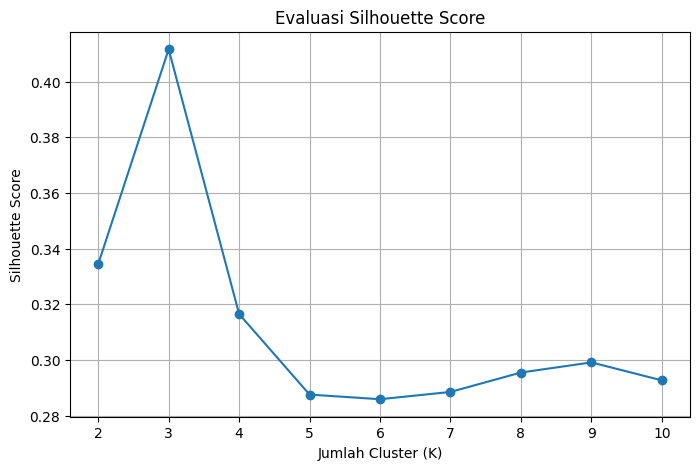

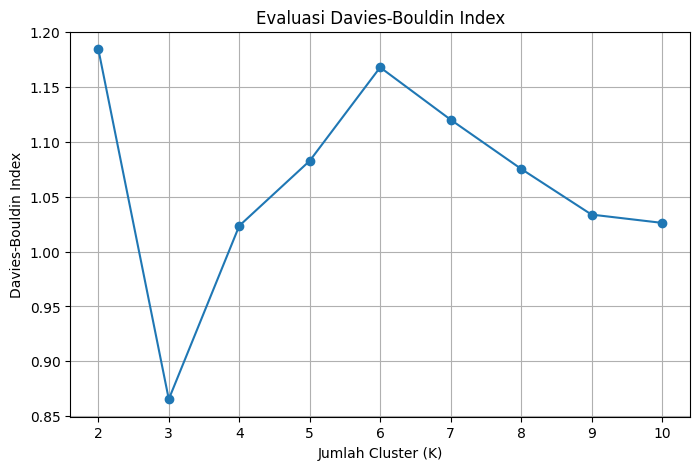

In [26]:
k_values = range(2, 11)

sil_scores = []
dbi_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df_norm)

    sil_scores.append(
        silhouette_score(df_norm, labels)
    )

    dbi_scores.append(
        davies_bouldin_score(df_norm, labels)
    )
scores_table = pd.DataFrame({
    'K': list(k_values),
    'Silhouette Score': sil_scores,
    'Davies-Bouldin Index': dbi_scores
})
display(scores_table)
# Grafik Silhouette Score
plt.figure(figsize=(8,5))
plt.plot(k_values, sil_scores, marker='o')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.title('Evaluasi Silhouette Score')
plt.grid(True)
plt.show()

# Grafik Davies Bouldin Index
plt.figure(figsize=(8,5))
plt.plot(k_values, dbi_scores, marker='o')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Davies-Bouldin Index')
plt.title('Evaluasi Davies-Bouldin Index')
plt.grid(True)
plt.show()

In [27]:
# ================================================
# FINALISASI HASIL CLUSTERING (k=3) — taruh setelah bagian Evaluasi
# ================================================
k_final = 3
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(df_norm)   # nama beda, tidak akan ketimpa

# Tempelkan label cluster ke data yang punya info wilayah
df_preprocessed['cluster_label'] = labels_final

# 1) Berapa total gempa di tiap cluster
print("Jumlah total kejadian gempa per cluster:")
display(df_preprocessed['cluster_label'].value_counts().sort_index())

# 2) Provinsi mana yang dominan di tiap cluster (top 5 tiap cluster)
tabel_wilayah_cluster = (
    df_preprocessed.groupby('cluster_label')['Provinsi']
    .value_counts()
    .groupby(level=0)
    .head(5)
    .reset_index(name='Jumlah_Kejadian')
)
print("\nTabel wilayah dominan per cluster:")
display(tabel_wilayah_cluster)

# 3) Karakteristik rata-rata tiap cluster (untuk interpretasi)
karakteristik_cluster = (
    df_preprocessed.groupby('cluster_label')[['Magnitude','Depth (km)','Azimuth Gap']]
    .mean()
    .round(2)
)
print("\nKarakteristik rata-rata tiap cluster:")
display(karakteristik_cluster)

Jumlah total kejadian gempa per cluster:


,count
cluster_label,
0,9922
1,30731
2,23126



Tabel wilayah dominan per cluster:


,cluster_label,Provinsi,Jumlah_Kejadian
0,0,Nusa Tenggara Barat,683
1,0,Sumatera Utara,437
2,0,Nusa Tenggara Timur,217
3,0,Papua,187
4,0,Maluku Utara,132
5,1,Sulawesi Tengah,2822
6,1,Sulawesi Selatan,1889
7,1,Papua,1256
8,1,Aceh,1074
9,1,Jawa Barat,911



Karakteristik rata-rata tiap cluster:


,Magnitude,Depth (km),Azimuth Gap
cluster_label,,,
0,3.6800,146.9600,111.7600
1,3.2700,19.9200,95.2500
2,3.2400,20.4100,204.9900


In [28]:
# output_path = '/content/drive/MyDrive/SKRIPSI/Data Gempa/df_final_fix_terbaru.xlsx'
# df_preprocessed.to_excel(output_path, index=False)
# print(f"DataFrame berhasil disimpan ke: {output_path}")

## 11. Visualisasi

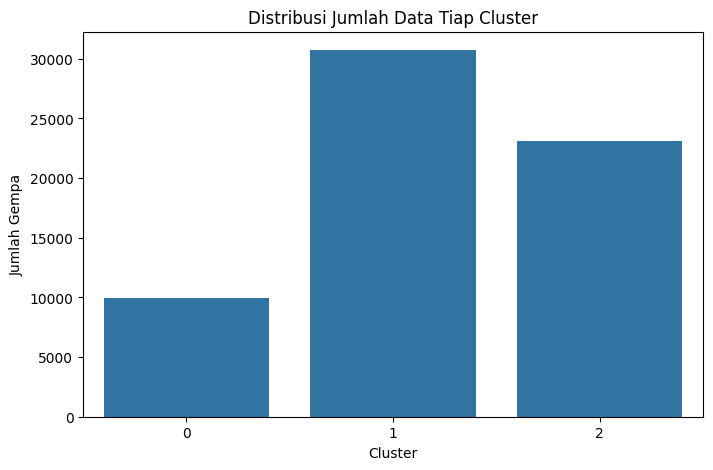

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

cluster_counts = (
    df_cluster_result['cluster_label']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title('Distribusi Jumlah Data Tiap Cluster')
plt.xlabel('Cluster')
plt.ylabel('Jumlah Gempa')

plt.show()

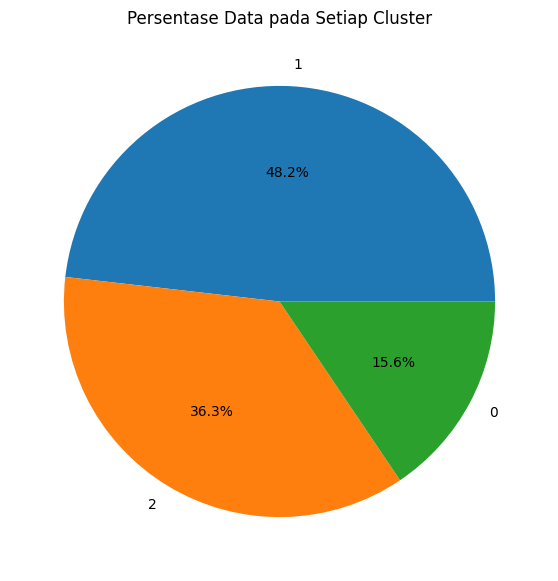

In [30]:
cluster_counts = df_cluster_result['cluster_label'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    cluster_counts,
    labels=cluster_counts.index,
    autopct='%1.1f%%'
)

plt.title('Persentase Data pada Setiap Cluster')

plt.show()

In [31]:
cluster_summary = (
    df_cluster_result.groupby('cluster_label')
    .agg({
        'Magnitude':['mean','min','max'],
        'Depth (km)':['mean','min','max'],
        'Azimuth Gap':['mean','min','max']
    })
)

cluster_summary.round(2)

Magnitude               Depth (km)          Azimuth Gap  \
                   mean    min    max       mean min  max        mean   
cluster_label                                                           
0                3.6800 1.0800 7.7400   146.9600  73  300    111.7600   
1                3.2700 0.9500 7.8900    19.9200   1   94     95.2500   
2                3.2400 0.1900 7.0900    20.4100   1  172    204.9900   

                                 
                   min      max  
cluster_label                    
0               8.8200 337.8500  
1               8.6100 151.6400  
2             148.6500 351.9500

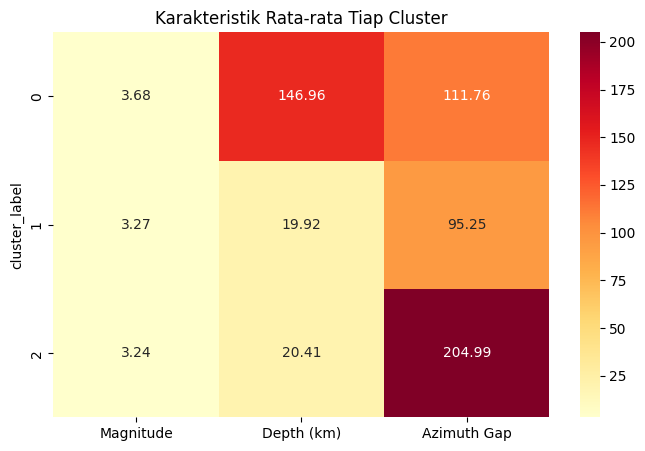

In [32]:
cluster_mean = (
    df_cluster_result.groupby('cluster_label')
    [['Magnitude',
      'Depth (km)',
      'Azimuth Gap']]
    .mean()
)

plt.figure(figsize=(8,5))

sns.heatmap(
    cluster_mean,
    annot=True,
    cmap='YlOrRd',
    fmt='.2f'
)

plt.title('Karakteristik Rata-rata Tiap Cluster')

plt.show()

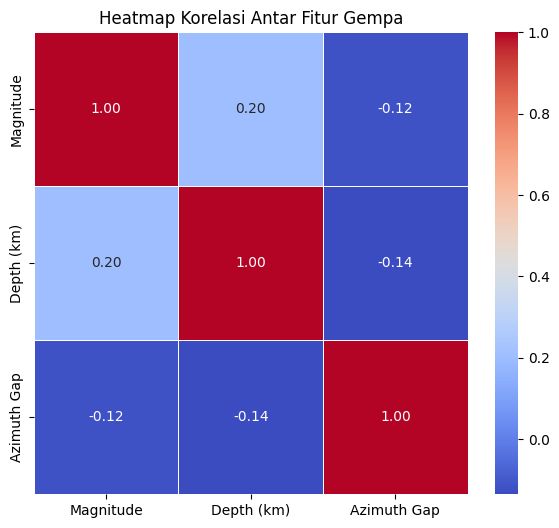

In [33]:
correlation_matrix = df_cluster_result[['Magnitude', 'Depth (km)', 'Azimuth Gap']].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=.5
)

plt.title('Heatmap Korelasi Antar Fitur Gempa')
plt.show()

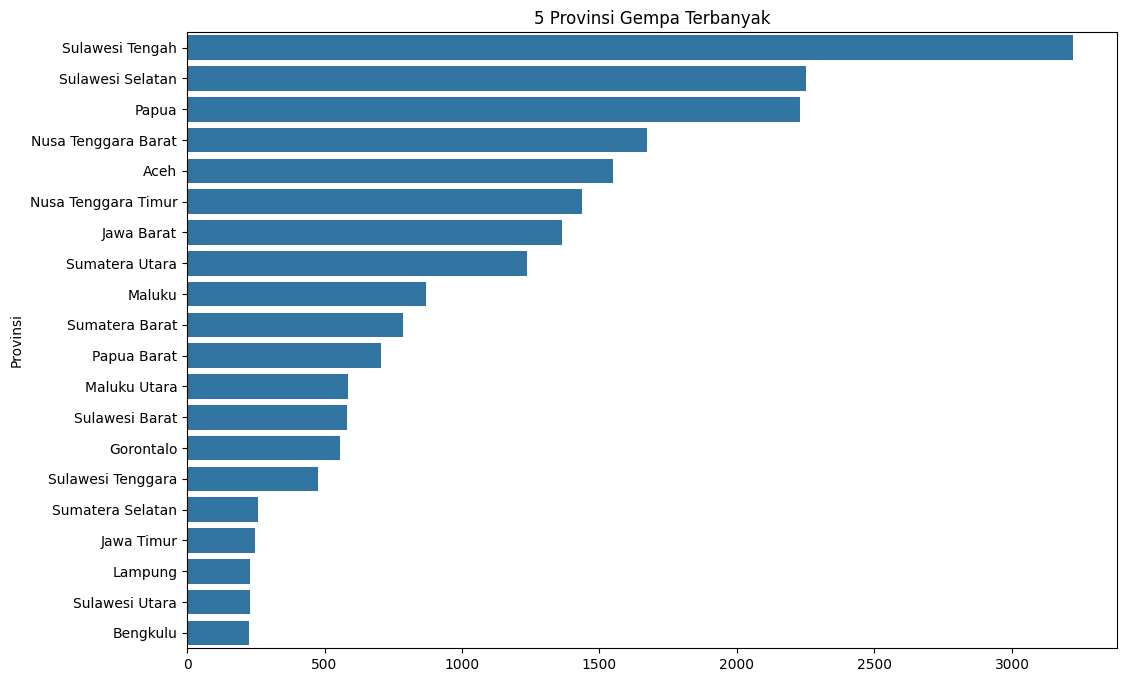

In [34]:
top_location = (
    df_preprocessed['Provinsi']
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_location.values,
    y=top_location.index
)

plt.title('5 Provinsi Gempa Terbanyak')

plt.show()

## 🔴 Selesai